# Figures de la Technical Note · SWOT WSE Toolbox 0.3.2

Placer ce notebook dans le dossier qui contient **SWOT_toolbox/** et **examples/**. Lancer les cellules dans l'ordre. Le mode **field** exploite les granules locaux de Belt Bay et de Madigan Gulf. Le mode **demo** teste les mêmes tracés sur une crue artificielle sans télécharger de données.

Les figures et leurs légendes sont en anglais. Les PDF sont destinés au manuscrit, les PNG à la relecture. Les sorties synthétiques, l'export archivé de l'Observatory et les nouvelles extractions ont des provenances distinctes. Aucun DEM personnel n'est nécessaire. Avec l'environnement de la toolbox, installer si nécessaire `matplotlib>=3.8` dans le noyau Jupyter utilisé.

## 1. Chemins, paramètres et stations

La période par défaut couvre 2025. Les exemples de références et de masques dans la cellule sont facultatifs. Le CSV de jauge utilise les colonnes **date,level_m**. L’index optique utilise **date,file** et référence des rasters géoréférencés (1 eau, 0 sec, autre valeur ou nodata inconnue).

In [1]:
from pathlib import Path
import sys, json, runpy, tempfile, warnings, hashlib, re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

# À adapter ici. Ouvrir ce notebook dans le dossier décompressé de la toolbox.
ROOT = Path.cwd().resolve()
GRANULES = Path("/Volumes/tfaraon_PhD/Data/SWOT/download")
OUTPUT = ROOT / "publication_figures"
START, END = "2025-01-01", "2026-01-01"       # UTC, fin exclusive
MODE = "field"                                # "demo" pour un test hors ligne
MAP_SITE = "Belt Bay"
MAP_RESOLUTION = 100                          # espacement du raster, en mètres
MAP_DATES = []                                # ou 1 à 3 dates UTC YYYY-MM-DD
SITES = [
    dict(name="Belt Bay", lon=137.028098, lat=-28.893022, bounds_m=[-16, 6]),
    dict(name="Madigan Gulf", lon=137.560000, lat=-28.893000, bounds_m=[-16, 6]),
]
# Facultatif. Fichiers absolus recommandés. Choisir le vrai référentiel de la jauge.
# SITES[0]["references"] = [dict(name="Gauge", kind="gauge", file="/.../gauge.csv",
#     datum="AHD", offset_to_raster_m=..., offset_source="Surveyed local tie", tolerance="1h")]
# SITES[0]["optical"] = dict(index="/.../optical.csv", tolerance="1D")
# Une référence LakeSP Prior peut être ajoutée avec kind="lakesp", lake_id, datum et tolerance.
# Les règles de filtrage, de sélection de fenêtres et de dates sont décrites ci-dessous.
OVERLAY_DATUM = "EGM2008"
FORMATS = ("pdf", "png")                       # ajouter "svg" si nécessaire
DPI = 450
if MODE not in ("demo", "field") or pd.Timestamp(END) <= pd.Timestamp(START):
    raise ValueError("Vérifier MODE et les dates.")
if not (ROOT / "SWOT_toolbox/stations.py").is_file():
    raise FileNotFoundError("Définir ROOT comme le dossier contenant SWOT_toolbox/ et examples/.")
sys.path.insert(0, str(ROOT))
for key in list(sys.modules):
    if key == "SWOT_toolbox" or key.startswith("SWOT_toolbox."):
        del sys.modules[key]
import SWOT_toolbox
from SWOT_toolbox import stations
from SWOT_toolbox.run import run
from SWOT_toolbox.optical import load_masks

if SWOT_toolbox.__version__ != "0.3.2" or Path(stations.__file__).resolve().parent.parent != ROOT:
    raise RuntimeError(f"Version attendue : 0.3.2. Module chargé : {stations.__file__}")
print("Toolbox", SWOT_toolbox.__version__, "—", stations.__file__)

Toolbox 0.3.2 — /Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/stations.py


In [2]:
# Un dossier par exécution : aucune confusion avec des figures d'une analyse précédente.
OUT = OUTPUT / f"{MODE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}"
OUT.mkdir(parents=True, exist_ok=False)
mpl.rcParams.update({"font.family":"DejaVu Sans","font.size":9,"axes.labelsize":9,
    "axes.spines.top":False,"axes.spines.right":False,"axes.linewidth":.7,
    "xtick.labelsize":8,"ytick.labelsize":8,"legend.fontsize":8,"legend.frameon":False,
    "pdf.fonttype":42,"svg.fonttype":"none","savefig.facecolor":"white"})
navy, teal, rust, grey = "#163f56", "#147d80", "#ae542e", "#58626a"
captions, skipped = {}, {}

def panel(ax, letter):
    ax.text(.018,.98,letter,ha="left",va="top",transform=ax.transAxes,weight="bold",
            bbox=dict(facecolor="white",edgecolor=".35",linewidth=.5,alpha=.72,pad=2.2),zorder=10)

def time_axis(ax):
    loc = mdates.AutoDateLocator(minticks=3,maxticks=7)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

def save(fig, name, caption):
    if MODE == "demo" and not name.startswith(("fig01","figS01")):
        fig.text(.995,-.026,"Synthetic demonstration",ha="right",fontsize=7,color=grey)
    for fmt in FORMATS:
        fig.savefig(OUT/f"{name}.{fmt}", dpi=DPI, bbox_inches="tight", pad_inches=.065)
    captions[name] = caption
    plt.show()
    plt.close(fig)

def omit(name, why):
    skipped[name] = why
    print(name, "—", why)

In [3]:
# Démonstration 0.3.2 : ses données restent séparées des observations du lac.
demo_dir = tempfile.TemporaryDirectory()
demo = Path(demo_dir.name) / "demo"
runpy.run_path(str(ROOT/"examples/make_demo.py"))["create"](demo)
demo_cfg = json.loads((demo/"config.json").read_text())
synthetic = run(demo/"config.json")
if MODE == "demo":
    sites = demo_cfg["sites"]
    for item in sites:
        item["optical"]["index"] = str(demo/item["optical"]["index"])
        for ref in item["references"]:
            ref["file"] = str(demo/ref["file"])
    data_dir, datum = demo/"rasters", "demo"
    map_site = sites[0]["name"]
else:
    sites, data_dir, datum, map_site = SITES, GRANULES, OVERLAY_DATUM, MAP_SITE
FIELD = "Synthetic demonstration" if MODE == "demo" else "KTLE observations"
methods = [
    dict(name="Point", radius=0),
    dict(name="500 m", width_m=500),
    dict(name="1300 m", width_m=1300),
    dict(name="Centre QC", width_m=1300, quality_mode="centre"),
    dict(name="IQR rejection", width_m=1300, iqr="reject"),
]
# Toutes les méthodes partagent levels=[0,1] et le calcul des quartiles sur l'archive fournie.
# Date de début et date de fin limitent les figures et les statistiques de période.
period = {"name":"figure period", "start":START, "end":END}
site_cfg = [{**s, "periods":[period], "detail_dates":[]} for s in sites]
cfg = dict(granules=str(data_dir.resolve()), output=str(OUT/"tables"), raster_datum=datum,
           methods=methods, sites=site_cfg)
config_file = OUT/"extraction.json"
config_file.write_text(json.dumps(cfg, indent=2, default=str))

1222

## 2. Test contrôlé et série d’archive

Ces deux figures se génèrent avant la lecture des granules de terrain. La figure contextuelle reproduit les observations du draft même sans disque externe.

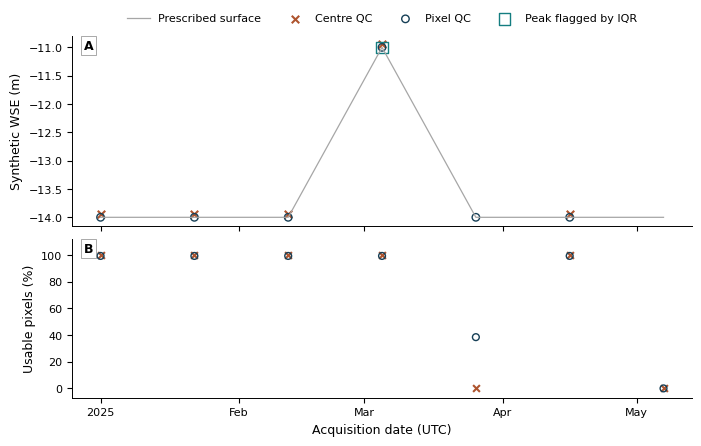

In [4]:
# Valeurs prescrites par examples/make_demo.py (jauge synthétique décalée de −0.2 m).
truth = pd.read_csv(demo/"gauge.csv",parse_dates=["date"])
s = synthetic["audit"].query("resolution == '100'").copy()
fig, ax = plt.subplots(2,1,figsize=(6.9,4.35),sharex=True,layout="constrained",
                       gridspec_kw={"height_ratios":[1.2,1]})
ax[0].plot(truth.date,truth.level_m+.2,color=".65",lw=.9,label="Prescribed surface")
for name,label,col,mark in [("centre","Centre QC",rust,"x"),("pixel","Pixel QC",navy,"o")]:
    z=s[s.method.eq(name)]
    ax[0].scatter(z.date,z.wse,s=29,marker=mark,color=col,facecolors="none" if mark=="o" else col,label=label)
    ax[1].scatter(z.date,z.valid_fraction*100,s=24,marker=mark,color=col,facecolors="none" if mark=="o" else col)
rej=s[s.status.eq("iqr") & s.method.eq("reject")]
ax[0].scatter(rej.date,rej.wse_raw,s=70,marker="s",facecolors="none",edgecolors=teal,label="Peak flagged by IQR")
ax[0].set_ylabel("Synthetic WSE (m)"); ax[1].set_ylabel("Usable pixels (%)")
ax[1].set_ylim(-7,112);time_axis(ax[1]);ax[1].set_xlabel("Acquisition date (UTC)")
ax[0].legend(loc="lower center",bbox_to_anchor=(.5,1.01),ncol=4)
for a,l in zip(ax,"AB"): panel(a,l)
save(fig,"fig01_synthetic","Controlled seven-pass test using the v0.3.2 synthetic flood at 100 m spacing. (A) Prescribed surface and estimates from a 1300 m window. The outlined square identifies the imposed peak removed if temporal rejection is enabled. (B) Number of contributing cells divided by the requested window area in cells. A missing elevation does not establish a dry surface.")

In [5]:
# Instantané de l’Observatory intégré pour permettre une exécution hors ligne.
import zlib, base64
bed_cm=np.frombuffer(zlib.decompress(base64.b64decode(
'eJztmnt8zvX7x5eFjTlMDsXMNodhzDbn8zkR3zK2YWSOaUqUEGFSSfkqOeWLlRw6IXJI5JRDcs65Qs4Vka/WDtf1we/5ft+3pWwz2u/x+/3R43rcn92fz/35vK/X+3W9rut9ve97Hgke/5i1bZoz45zVMTrxb421TaO1gLbXzn9rlAE6Tw7L7e/rrUUy9XNE+qqvE6bdsjFO5vaI1pWG8nOWY1ySQzJVXpIQLez89TNHfHSGHAbl0/ribZDc+vTNNlIbgqSRvCNvZzLn9WB4UcbLEGycNNWS9r5U99395RVZKUt0OxEalskI5t6Dukif1d1ZxG+CNpA60ljaSPhf7srjTNNP5Li8JgNlDP6GSH/evSkT5ZT8gaS7jJX/cn41Cx/rtLW+LyPkKWZUJ9P73tDGEib1pMstzB7TufK8fCSjJR4Uw2WA9JI+8qyMFC/9TG8gGQuyD7NA8a120HHSV7rhIVZiJEr81CPDKA3W6lJVlsgH8tcRPmAWfaWnxEkPXr2lu3S1Z/1kl3yObjbKFhBshkufTOO/UBvqSBD0sCj+JY9ItHSUbyQpA+wpUkmqSQl9DP5vvr4THvrgvTu+DYYY6cCsngVbNByNgWdjhyQqCz5Gaoq8xf3defZBFFAXawaeXpKSgbZXS4jUAMUkmfSnMffIk8ykm8XSTTpbXjvAzCBeHdHLKEkAyRWppW9kimWT/ihDeTZKmqCAEKnIq5o0kPbS5JZnpugqCQfpyAwwfsZsHoONTqDownidOI/ifCBXu8lgnnlBXpe62ikTJNc0Tj9kHo+QmaESLOWlHBYkFaS1LLjlmcXaXGox3q3XL+sWNTyYuHYCR1cslncdbayiYWYweh4tlXRdhlWkkJOiJ+UZaSctwVFBAqWM285Kvwywf04ON5HpfxqrvnrpcJkrO5l5JNYB7x3gpbM1o5corAdeEojRWJmcISfXdbBOJg4PwXlZ/PuLH1aaV2iGyHdLU2mF1z+ueOvr8hwa6Y7/KIsh0lpHeOjkjlCkVe8w4pMggZo7w8zZozuIY3N0GmyZKG2RGItO97bDPYeu4sFK0YKaNuwmJI30BVQZj6cOlg2DJpK5RVpeYqxyDbIYYvMCNXdchozkc0K1P3w0Q6VlbmKktERQM7bLGZmj59TE0CNhuEahpWZkVzvGvTFCPX0ZD/HExXARZc1gaO/G0gFWXEi6Um3Gisq9GTKyX5dyz4NSH4UaHDcYMVgqga6ZPCGz3V4PMGpr1NSa/O5zEydH4TTOrYauMBNl/Ue6jx0tJ4alTlavH2fIyBWdrROZZ2vWEZMt/umRMRYklWGmNfp33T2LO9tg7fg7QFzPs5oQqd7Wf2d46cox2o3Bpdxoy0mMRfQcK2NmGdxRJ/FEW2pHCHoNvEklfpxVo4K1TF9fBjGmif+j7lpySEvpJsYeYOtprK3wna3PyHTrYFGYTw2SZ+RleTITJN/Q9ZiItiQ+1agkgTfFJ4DoRJCxcXLEen4eX12wGPnJnreFz+fBEWerRw93Tetks8elkkh3dEwudwTNEHSXMQ6PhOV6wmosmmfagCacKJWxKvEnOuVRbU0YW2jn0ZPqH4e/OXa0tTrH5m4PW017oJw4iyXGxqa921y5bKptB5CMlPWZ1vl56qnx3BNn4xkNmoY2TuV4BVNRqlNPG8piXazn+bSbLJNe7rGK6FDW2B42HrEgehosPW9CEunOZIOkq41OnFySHzJF0ksPs1rG09H05diXWcei0eZUr3popCa50xZ9RuFzMCMNoBMwOdheF8qrNmNiLf7OYvjqZVfiaHc1aW+PHe0KZDIqmq5ncSY48jv3OIV0Ozoago9BdDZP4bE3z0XKw9SvZlS7dvDwGDPvbfl/mso0mtFm6Xz6ssE2MjG2lsWCxdzRy66jkek6MRqJtXi74KV6JkiSdSsd5gV6rPz6GvwmMM/xqHsgNaQ/vuNhaxBr9DD7dyAjjeAe8+RMXSSTUevjeHetcqaWG510t1nsUmqUZcv0CAbvAInPNDI+zijtrflYvYTuNh49TaSvmgyWIfD0DL3NFM4MttHwNQRMI2W+XLPjRdCdvwjCfrYr6gUjHd3rXbS7nkVb6ww6g7QfY6dm0cd7Oq/rLjvyI6xiY2WazJCZeH8R36PkDVksn9rzicTC1PSh8mv6aKu5NsKuN33gcwiR7cbMo2396Gy1EWtz2kQnXt6VZ7O1x/JychGfN6nrc/A9Gy7GywSOy2Q3FWC+zOL9JGI3nN3BwvQR54J2EGoZTvxGYcNA8yS4+nPsj8XDlam6/ZjFtGzu9R7VrZIo76OYT+ULWS6LQPQWDC2R4tTRzfIhzEwjcuOoqF/Jl+mjjtBhaHgkDI7ms7GWyVEcx1pWR9r9znOMXDX7e046wi/wu0w+kw2yTtYz9znYIvHXoroXfB9xNgM0b8i/qSjX2DGsUW9nIP3Ay3gcBmNTYfFVerlpVl1Gce9wnCCfuJWVHfuCnu2g7JAtshkUu+y7taCYh/+LdCTHZBs8LWDk2XDzJvuFX/V7SWLPsMh27GNlqTTSZXz2FogS6aKmgma2RT5LGmQTh5ezQ+fpWdlP53ecHcAJ+Z7jdtB8CkcLZS9YfuR8vcUyDz/TmGkQlW0+830NPb0CD83wdghVJsp/5D3uW2BjnYhtzTYfF9iZFtMzrHG7QXEMfZ4Dyw52OmtB8jH4fmIvvh9WNjDzD/E20yp5GrOfSDc7CRxTZAz+joPBfDoHjAuoxR/BTEuun1FHb+3Lb7U6Wkivs0u9IN/KaTkJjsvsSE6C5gBR+ES2cv07zvbLHvkSLX1o9uXYHNifBQMGyXSZgqezfObCsIDsXygrYNIjYZlO1iX6km65LZZB5AaVTa4yd2OnJE1+h5sjKGcvc98Cgv282wdPm+FpOf5mM/d5VjVTiNBbxOC0eDuf22iuBP1SnvuUe81eaaOO1Rd5nbktksLOLJDcox6aJgI3SWBSODiM+eoKWS1fM7e94DiEQteAZCEYEi0f/yFHpnH2Hhi+5PpSWQWGxfxdAiObxIGT4/qm7tUT2VKLp+OnuekNPDVZfoGVC2j0B+wo+3uTzQbJPrAcsDm1Cu0YLc4Gx3Si8Q78vI99bGvAUvAs4p7lxHEP92e8m8jM8jj+6sPq4w0rSbByHoWeIl9OwsomxtxMXu/mvVHKV+h2CVp8DyTTbZ4YbuaQt4vA8TlMrOCJ9Zj59iv5Dr+5yu2EaREtCJaraPUKMb/I8TfwHGDEZby2kUHfodxviMFafLniMx0zqp2LZuYTkxXwtwI060H+tRgUee7w27wNGqQlyOT7wJJK5lxCs1fQTDJqWcfoGxh3H7XmNHjWgmwhmp1L1ZqEVqdYnSSSLyfJsuXEZT1/94H5nPg4998hkqs6QcP0AXKolBbQFHDcq79JXlCdQBfL4WEHOH4mbkeJzkqwuJQy1XYQporOJG+Pw6BRxyZieJQ5nKNPPC9nwXJJn9Du2cXkvAIvJWHGZHQafYSIyezz6GMlOjlIVl+gH/gRrWzEl4lQIlV/MpxMJULvEJvV3LsKPr4ijsfBYXoRlYfU7HZ3k4/ZQ3JGx2stLa1+MFMQtThyD5mUCgv7iPtWcJwGRxJofmS2R8nn9UQo0eokET4+4q51YPgKNEdQ+wnmcEkqk5Ee2hEseTVJquiebPCyS58iPgEg8UMvXppHc2leKu9FMmA1LJwkt6/INV6X5SxefiKvV5Mt74JiIbm0Cgw7Qb0L9k6C+ix6T6EaFSbaT6iPU4D1vJXmum1G3+OM1CitqZU0ECvJ8yajvcByhaqyltlehJ1U9KOg+Z1jKuwfQBNrwLOW4w7y6pTN86PgPM/qfS/c+mmI+quvVmO8JlowG5XF0xmh3bQBT5SBlwC0YnAYPNeZ32Yicc1t+fDgCeepzPk0tW4PWbWXWBn/v7B2XiSGKRavef4BDQVNKWYXS5f8x7yzwrJKu4I6mBn4g6QsY/ii3sJ4/RmVbBRPUOUB371UwLy8c1BSEr5N7TuNen62q2aKReGgzjQpyBiltQJWVvv+SR97s1DLlzpGH9Qqlg2DpALHMkTJeE4ijzeS0UWJeH67JuQBi1kZjK6TwZMCP5fg4rKIrUEpkgudFmacIMapQIR23uR7mX6bKZJk3a2v6MOgmK8HmEeAlmce/sypMJ6vocRNRKWIjZZhpqA95oYXAcvvaCYJFJdBcJWomJzLxctXKzOOv1bUdoz6h7djt8mfr9ORPk5Ug5iJQXM/nUteetgtUghOzHpQDKb8wFTQVuMUGPiNl4uZFFNBWNPZOkluOA0jAypqsz99F/21e0eTHWthIxOMmRmVYgU4TG76gqEA7/20HAhNpEoy8zT0kOzG46qG1zHl7LpU0HD0Wo5+0DsdyYU7qv0J4AiEEzOfcsSqmJp1r7BFUgwkhi0/3t+Phkx8UolPGr7/C56rNjbXwebJGFXJxQB9Ld17U70zJPc5EWjXcFIJn2WIw/dU76JwUJRsKs/VIMbPryYCHqg21UYllfxNwr8Xn+SDLW/uDtKnNU5/td4f1rd5dqUbyeFsIdqjLWxkqqJ5k9WF1awiZlw/eKjIJ/cz3wdsJudSk7NptuYlg8MH3EV55YcZlWD8ufafVen89tlzl03KFpLr2osaF0yUjQUy+j5WEYOkOP7LYqb6lbBVxYvZX7P6SCMuvsTyfnT9gK3SPlrD7DvU9MmfUIf3SB6dy9ka/VzXyOPZwLJKn0HvZbU21b82iLx1D/XzAXdUjE5K4y03OHxA4gmS32zO5AWBqR4BcBnCvUVhNZfj2ut00aFkUjK7yWo87anbWJ2evy2WvFT+lkShLjjqURM8dScKKGn1WwkkARwLolizurmicF7M74v54CwYJIZNozM/fPbQtW5/Ps53xLUw2RdDn++n1dl33J6V6SilgtahS6hFdBw6x2tiKlRFPFSzkTGZVJxak588SaPap0kBeArEV3mwhxOXMMzUyE2u7wmtwgbqVnVxlN85mS2lvKWNwVyX8Ux0roPE2+rDrCHV8BUAjmKwb3oHE5vDcOZjfZXj/gCiUoun64Kpim7WHfou63wVPZzJbwZZWaK2gZF6Fk1ZfG1nxhVBUZK4VLFWCk0UQiu5sCt0AknUmxJ4Nr5DQFtTG6H6+pzXYTYRrDtpd/U7+Tesyw0ZqTarc2Vqxm4pQbWsbBVSCT9hzD0QJXurWemS6VMcuY8rIfbTGuCoieabwKxRfQ394K5/rT+CqurDcH1mVkV/R+dBeA+3bITyztQZ02P62pUwleioFOGq+bSGRdKUEVqAxJy104t3jWS9drDRqQ2WKnTnJ6hJ1TmrBRqDo6LN5KKgMXmcQt+ajyiG2nWmOnfV0dZUDk8nwc5lxN/4/4WhzKMauqvOSBX0KP1QqM2HuniJsNxUpLr5k4tF7M7+mBS3bETwVBU+r+X+tbGQ8zDd9Ny/gWSwPgoDZuzGeDxI9QzjvZmtiXs4GCvZNSmI6uBNdE5JOTAYnAaNwfqCFrF58jZVMjv9fMaWRD3siuJMTWhM1dhLhppVNRRf4eAJA0MIVyrbOppHL8OZydt6RKUBx/raXq+4ved2st+N3GrvgKQbeqvBqPXI1W8k0OKIsFYDBCHWjFbuIzrn6QoMPhPLB4nGEHc1+7v2m86gt3nMVhQTDw90Em5ZD0tHUNXWdLPCFEezyazItbi3DtZDX6KKOzmCpIjzAUh6wXAjq4lf6E9r4CnM5k1lXlXIk/LuTiqY+Dh0lqaCVMVa6ct6Nof++8j8qj9CHyePG8N2CP2aL17C8FoZ33VAYFZkf2qb60oJFOtNpXd1Vf+Ckfx3XNMzs206SvtZJA3I0wMSoqaHKweGCHyXsTuiMrbnrop6Aqiz99i12Y8qG6dr1DfHkOzQ0eyUHoWR2nSqp6Uu8w3Ad1mQBFoc/rbPDbErczDr8nX6k6vs+UrDZkqOxcbU+jEgeYRI1NSLrCh18BcEkvJ4DQKDQWU6lRAYqcbRdAf56JOKsEIOzUEcpnscgWLbki+hdLAl7FpqGKll63hNsiQc/4G2tw62lb84bATa3rK/u6LlhPk67+tg6kkrfJbXQ1KZv+XgIZwrbVFkW/L7IdbZmmgmlPpXHbWUBGcgqvXW93KMEy+nOdUpBn9Nmb8/mROBXuqDw6yuPbU3bPXQ7vaOxuAYoJN1JhU5wuaUIwNyDMl+1q5W7JCb4qcm8f9BaoLD1NrO+gQqGIEN1+f0KVDFaDQd6VLdp1/rD7pfvXIsLuZ7P/OtWH/W9BZ0SqFkzkk4aQiqzqAYrq/SB84jAjN0PGcDNF6ngGQB/WHW34jcjZ2F6YFkcBNWO1Mpjkkp3jekD+2tffR1VpQD2G6qxnucjdYJ+gqv9XfRod7eNlgkDaiqpaifDjvNhmqsDXGboNv1Gl5zOZf0IL3yav1Cl4NqnR7PEX18R4zN/zge1en6CfFvzopTHw1WJTe99BzxqWXX4E46kTjcXMs9HbNOmXf35RgnB3UScemJQhoRDWMNiE8I9fM8vUd98ihUu3DPziz+Ly+nrKDTFjZMtWhJvYjkWMPuMXKj27pEpz2r7Eyy5BfNWQ5uWCFnrZr/KvVyNutKuN9OLszQcZrAatzK9opBar79LKWx+rH+m73lkWx8p3rndlXP63f6qZmlY6prQecK2tuhq8jMSaAZSMdUm5qeRs9clcjVJ2/y/q9H54Z5O8l6Wg+h4i2w9D61Kxp28rLrKQJPXk7OxyUrK+B4OnkdL0dRxSlY+hbe7kW7Q3J0pb1b20hFT/x/geQf+8f+7+1/AKxkQnQ=')),dtype="<i2").reshape((94, 69))
extent_km=[677.715, 781.215, 6778.121, 6919.121]
archive_coords={'Belt Bay': (137.028098, -28.893022), 'Madigan Gulf': (137.56, -28.893)}
archive_daily=pd.DataFrame([('Belt Bay', '2025-05-12', -14.971), ('Belt Bay', '2025-05-13', -14.8235), ('Belt Bay', '2025-06-22', -13.181), ('Belt Bay', '2025-06-24', -13.304), ('Belt Bay', '2025-07-13', -13.223), ('Belt Bay', '2025-07-15', -13.32), ('Belt Bay', '2025-08-24', -13.2945), ('Belt Bay', '2025-08-25', -13.3175), ('Belt Bay', '2025-09-14', -13.427), ('Belt Bay', '2025-09-15', -13.4945), ('Belt Bay', '2025-10-05', -13.494), ('Belt Bay', '2025-10-06', -13.737), ('Belt Bay', '2025-10-26', -13.682), ('Belt Bay', '2025-11-15', -13.9695), ('Belt Bay', '2025-11-17', -13.925), ('Belt Bay', '2025-12-06', -14.371), ('Belt Bay', '2025-12-08', -14.0185), ('Belt Bay', '2025-12-29', -14.235), ('Madigan Gulf', '2025-05-12', -14.3065), ('Madigan Gulf', '2025-05-13', -13.697), ('Madigan Gulf', '2025-06-03', -15.362), ('Madigan Gulf', '2025-06-22', -13.8865), ('Madigan Gulf', '2025-06-24', -13.8645), ('Madigan Gulf', '2025-07-13', -13.5095), ('Madigan Gulf', '2025-07-15', -13.6825), ('Madigan Gulf', '2025-08-05', -13.402), ('Madigan Gulf', '2025-08-24', -13.2865), ('Madigan Gulf', '2025-08-25', -13.2265), ('Madigan Gulf', '2025-09-14', -13.386), ('Madigan Gulf', '2025-09-15', -13.275), ('Madigan Gulf', '2025-10-05', -13.478), ('Madigan Gulf', '2025-10-06', -13.6485), ('Madigan Gulf', '2025-10-26', -13.5795), ('Madigan Gulf', '2025-10-27', -13.634), ('Madigan Gulf', '2025-11-15', -13.931), ('Madigan Gulf', '2025-11-17', -13.7665), ('Madigan Gulf', '2025-12-06', -14.117), ('Madigan Gulf', '2025-12-08', -13.932), ('Madigan Gulf', '2025-12-29', -13.965)],columns=["site","date","wse"])
archive_daily["date"]=pd.to_datetime(archive_daily.date)


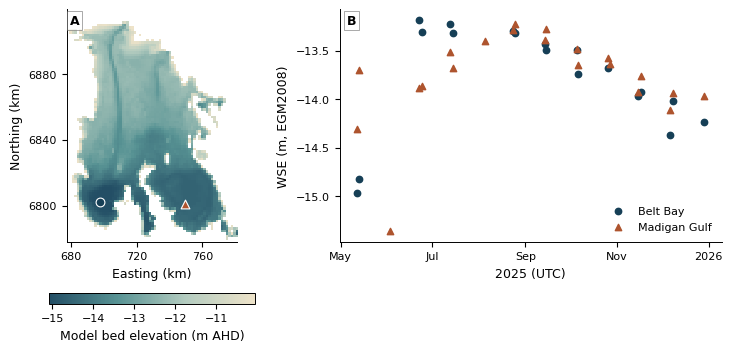

In [6]:
# Figure contextuelle correspondant à la série présente dans le draft HESS.
# Le domaine coloré est le domaine bathymétrique du modèle, pas la rive de 2025.
from pyproj import Transformer
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
bath=np.where(bed_cm==-32768,np.nan,bed_cm/100)
fig,axes=plt.subplots(1,2,figsize=(7.25,3.4),layout="constrained",gridspec_kw={"width_ratios":[.95,1.55]})
a,b=axes
cmap=LinearSegmentedColormap.from_list("depth_ktle",["#234e65","#589394","#b4ccc0","#eee3c9"])
im=a.imshow(bath,origin="lower",extent=extent_km,cmap=cmap,interpolation="nearest",aspect="equal")
a.set(xlabel="Easting (km)",ylabel="Northing (km)")
a.xaxis.set_major_locator(MaxNLocator(3));a.yaxis.set_major_locator(MaxNLocator(4))
cb=fig.colorbar(im,ax=a,orientation="horizontal",shrink=.88,pad=.05)
cb.set_label("Model bed elevation (m AHD)")
transformer=Transformer.from_crs(4326,32753,always_xy=True)
for site,col,m in [("Belt Bay",navy,"o"),("Madigan Gulf",rust,"^")]:
    lon,lat=archive_coords[site]
    x,y=transformer.transform(lon,lat)
    a.scatter(x/1000,y/1000,s=40,c=col,marker=m,edgecolors="white",lw=.8)
    g=archive_daily[archive_daily.site.eq(site)]
    b.scatter(g.date,g.wse,s=21,marker=m,color=col,label=site)
b.set(xlabel="2025 (UTC)",ylabel="WSE (m, EGM2008)");time_axis(b)
b.legend(loc="lower right")
for axis,l in zip(axes,"AB"):panel(axis,l)
archive_daily.to_csv(OUT/"observatory_2025_daily.csv",index=False)
save(fig,"figS01_observatory_2025","Kati Thanda–Lake Eyre North. (A) Model bed elevations from the KTLE Observatory bathymetry cache, sampled on a 1.5 km display grid, and the two fixed stations in UTM zone 53S. The colour scale describes bed elevation in AHD. (B) Daily median WSE from the archived site export on 18 dates at Belt Bay and 21 at Madigan Gulf. Symbols are not interpolated. This archived series is distinct from the granule extraction in Fig. 2. Source: KTLE Observatory, revision df08a608a43afdcdfb0b927a071b40014c3dadc2, data/bathymetry.npz and site/data/swot_wse.json.")

## 3. Traitement des granules et table des survols

La routine de la 0.3.2 relit l'archive pour chaque site et chaque méthode. C'est l'étape longue. Garder le noyau ouvert pour modifier puis réexécuter les cellules graphiques seules. Le filtrage temporel est calculé sur toute l’archive fournie avant la sélection des dates à afficher. Les granules illisibles sont signalés dans l’audit. Un survol est identifié par son cycle et son numéro de passe, séparément à chaque résolution.

In [7]:
if not data_dir.is_dir():
    raise FileNotFoundError(f"Renseigner GRANULES dans la première cellule : {data_dir}")
tables = run(config_file)
audit = tables["audit"].copy()
audit["date"] = pd.to_datetime(audit.date, utc=True)
def utc(t):
    return pd.to_datetime(t, utc=True)
audit = audit[(audit.date>=utc(START)) & (audit.date<utc(END))].copy()
# Une observation par station, méthode, résolution et survol. Priorité à la tuile
# acceptée avec la plus forte fraction valide, puis ordre stable du nom de fichier.
group = ["site","method","resolution","cycle","pass"]
eligible = audit[~audit.status.isin(["outside","unreadable"])].copy()
eligible["accepted"] = eligible.status.eq("accepted")
series = (eligible.sort_values(["accepted","valid_fraction","filename"],ascending=[False,False,True])
          .drop_duplicates(group).sort_values("date"))
series.to_csv(OUT/"plotted_passes.csv",index=False)
if series.empty:
    raise ValueError("Aucun survol couvrant les sites dans la période. Vérifier les dates, coordonnées et tables/audit.csv.")
resolutions = sorted(series.resolution.unique(), key=int)
site_names = [s["name"] for s in sites]
selected = series[series.method.eq("1300 m") & series.accepted]
print(FIELD, "—", len(series), "lignes méthode/site/résolution/survol examinées.")

/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/run.py:35: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  audit = station(granules, site["lon"], site["lat"], optical=masks,
/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/run.py:35: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  audit = station(granules, site["lon"], site["lat"], optical=masks,
/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/run.py:35: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed 

KTLE observations — 430 lignes méthode/site/résolution/survol examinées.


/Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/SWOT_toolbox/run.py:35: RuntimeWarning: NetCDF read errors for 8 acquisition(s); 8 without a readable copy. First failed file: /Volumes/tfaraon_PhD/Data/SWOT/download/SWOT_L2_HR_Raster_100m_UTM53J_N_x_x_x_003_435_053F_20230916T112924_20230916T112945_PGC0_01.nc. See read_errors for details.
  audit = station(granules, site["lon"], site["lat"], optical=masks,


## 4. Niveaux locaux par station

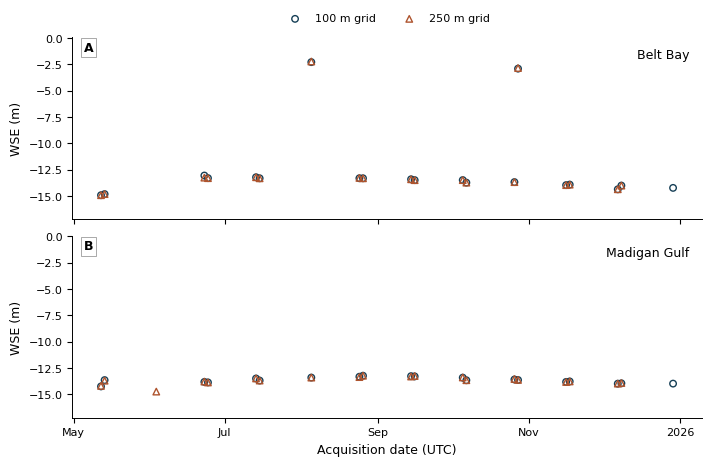

In [8]:
fig, axes = plt.subplots(len(site_names),1,figsize=(7.0,1.95*len(site_names)+.65),
                         sharex=True,sharey=True,squeeze=False,layout="constrained")
symbols = ["o","^","s","D"]
for i,site in enumerate(site_names):
    a=axes[i,0]; panel(a,chr(65+i))
    a.text(.98,.94,site,transform=a.transAxes,ha="right",va="top")
    for j,res in enumerate(resolutions):
        g=selected[selected.site.eq(site) & selected.resolution.eq(res)]
        a.scatter(g.date,g.wse,marker=symbols[j%4],s=22,facecolors="none",
                  edgecolors=[navy,rust,teal,grey][j%4],label=f"{res} m grid")
    a.set_ylabel("WSE (m)");a.margins(y=.18)
    if not selected.site.eq(site).any(): a.text(.5,.5,"No accepted estimates",transform=a.transAxes,ha="center")
axes[0,0].legend(bbox_to_anchor=(.5,1.02),loc="lower center",ncol=4)
time_axis(axes[-1,0]);axes[-1,0].set_xlabel("Acquisition date (UTC)")
save(fig,"fig02_station_levels",f"{FIELD}. Local surface elevation in the {datum} datum. Estimates are means of finite pixels in quality classes 0 and 1, in a nominal 1300 m square. Symbols distinguish grid spacing; each represents one accepted cycle/pass within a resolution. Dates are not interpolated. Windows at 100 and 250 m spacing span 1300 and 1250 m, respectively.")

## 5. Disponibilité et différences sur passages communs

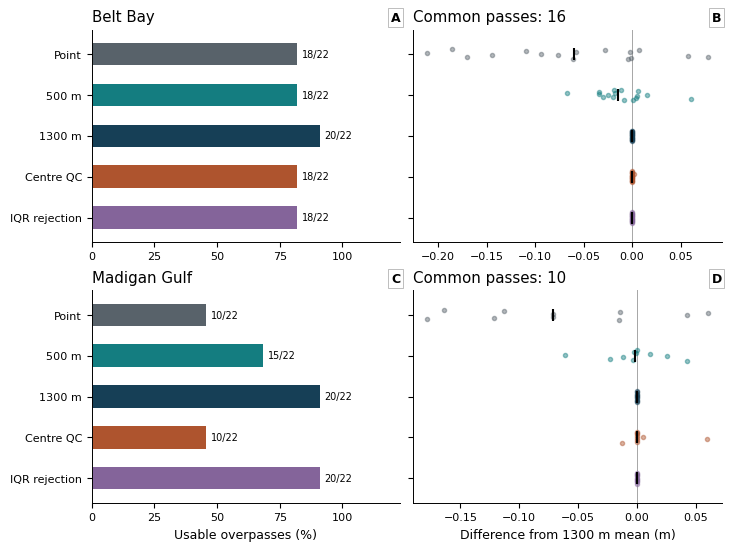

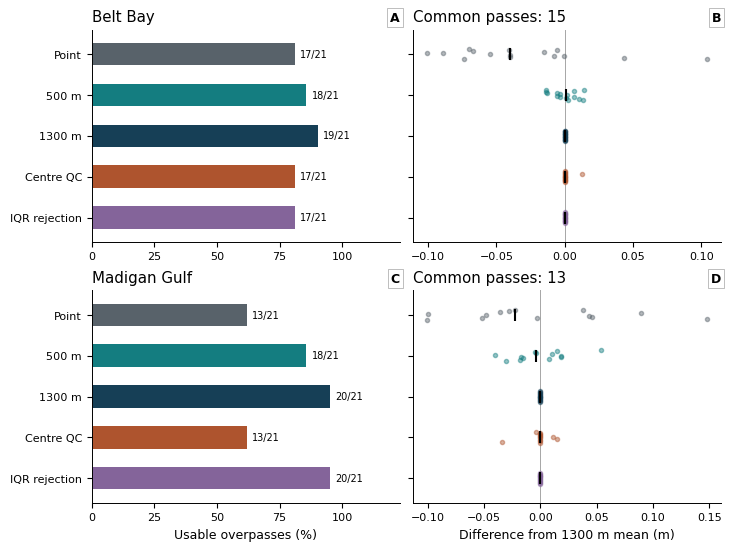

In [9]:
# Différences appariées entre méthodes. Elles quantifient un effet de traitement, pas une erreur verticale.
method_names = [m["name"] for m in methods]
keys = ["site","resolution","cycle","pass"]
wide = series[series.accepted].pivot(index=keys,columns="method",values="wse").reindex(columns=method_names)
common = wide.dropna().reset_index()
common.to_csv(OUT/"common_method_levels.csv", index=False)
counts = series.groupby(["site","resolution","method"]).accepted.agg(["sum","count"]).reset_index()
counts["percent"] = 100*counts["sum"]/counts["count"]
colors=[grey,teal,navy,rust,"#84649a"]
for j,res in enumerate(resolutions):
    fig, axes=plt.subplots(len(site_names),2,figsize=(7.2,2.35*len(site_names)+.7),
                            squeeze=False,layout="constrained")
    for i,site in enumerate(site_names):
        left,right=axes[i]
        n=counts[counts.site.eq(site)&counts.resolution.eq(res)].set_index("method")
        cm=common[common.site.eq(site)&common.resolution.eq(res)]
        for k,name in enumerate(method_names):
            if name in n.index:
                rec=n.loc[name]; left.barh(k,rec.percent,color=colors[k],height=.55)
                left.text(min(rec.percent+2,102),k,f"{int(rec['sum'])}/{int(rec['count'])}",va="center",fontsize=7)
            if len(cm):
                d=(cm[name]-cm["1300 m"]).to_numpy()
                right.scatter(d,k+np.linspace(-.13,.13,len(d)),s=9,color=colors[k],alpha=.45)
                right.scatter(np.median(d),k,marker="|",color="black",s=65)
        for a in (left,right):
            a.set_ylim(4.6,-.6);a.set_yticks(range(5))
        left.set_yticklabels(method_names);right.set_yticklabels([])
        left.set_xlim(0,123);left.set_xticks([0,25,50,75,100]);right.axvline(0,color=".65",lw=.7,zorder=0)
        left.set_title(site,loc="left",pad=6); right.set_title(f"Common passes: {len(cm)}",loc="left",pad=6)
        for k,a in enumerate((left,right)):
            a.text(1,1.04,chr(65+2*i+k),transform=a.transAxes,ha="right",weight="bold",
                   bbox=dict(facecolor="white",alpha=.72,edgecolor=".5",linewidth=.5,pad=2))
    axes[-1,0].set_xlabel("Usable overpasses (%)");axes[-1,1].set_xlabel("Difference from 1300 m mean (m)")
    save(fig,f"fig03_sensitivity_{res}m",f"{FIELD}, {res} m grid. Left: retained/eligible cycle–pass counts for each configuration. Right: paired WSE differences from the pixel-screened 1300 m target window on passes accepted by every plotted method. Short black ticks indicate medians. The point, 500 m and 1300 m windows use per-cell quality screening. Centre QC gates the 1300 m window using the central cell. IQR rejection removes temporally flagged values from the 1300 m series.")

## 6. Empreinte des estimations et déplacement des pixels retenus

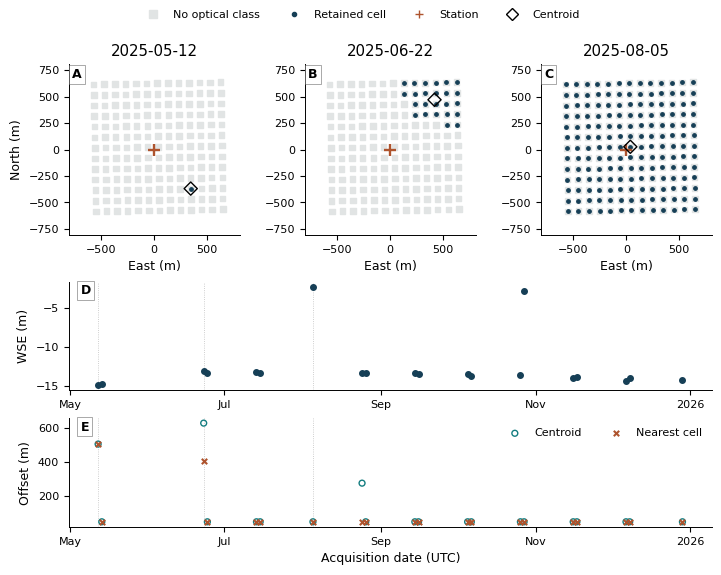

In [10]:
# Lire uniquement les granules retenus pour les cartes. Aucune nouvelle passe sur toute l'archive.
map_candidates=selected[selected.site.eq(map_site)&selected.resolution.astype(str).eq(str(MAP_RESOLUTION))].sort_values("date")
if map_candidates.empty:
    omit("fig04_footprint","Aucun niveau accepté pour MAP_SITE et MAP_RESOLUTION dans la période.")
else:
    days=map_candidates.date.dt.strftime("%Y-%m-%d")
    if MAP_DATES:
        if len(set(MAP_DATES))!=len(MAP_DATES) or len(MAP_DATES)>3 or not set(MAP_DATES)<=set(days):
            raise ValueError(f"Choisir 1 à 3 dates distinctes parmi {sorted(set(days))}")
        chosen = [map_candidates[days.eq(day)].sort_values(["valid_fraction","filename"],ascending=[False,True]).iloc[0] for day in MAP_DATES]
        rule="User-selected dates; on a date with several passes, the accepted pass with greatest valid fraction is shown."
    else:
        # Trois observations illustratives : première, niveau maximal et décalage maximal.
        # Les ex aequo et les doublons sont complétés avec des dates réparties dans la série.
        distinct=map_candidates.copy()
        distinct["utc_day"]=distinct.date.dt.normalize()
        distinct=(distinct.sort_values(["valid_fraction","filename"],ascending=[False,True])
                  .drop_duplicates("utc_day").sort_values("date").reset_index(drop=True))
        candidates=[0, int(distinct.wse.idxmax()), int(distinct.centroid_distance_m.idxmax())]
        candidates+=list(np.rint(np.linspace(0,len(distinct)-1,min(3,len(distinct)))).astype(int))
        candidates+=list(range(len(distinct)))
        ids=sorted(list(dict.fromkeys(candidates))[:3])
        chosen=[distinct.iloc[k] for k in ids]
        rule="Illustrative dates target the first accepted date, maximum accepted WSE and maximum centroid offset. Repeated selections are filled by chronologically spaced dates. This selection is descriptive."
    cfg_site=next(s for s in sites if s["name"]==map_site)
    optical=load_masks(cfg_site["optical"],config_file.parent) if "optical" in cfg_site else None
    fig=plt.figure(figsize=(7.1,5.65),layout="constrained")
    grid=fig.add_gridspec(3,len(chosen),height_ratios=[2.1,1,1])
    details=[]
    for k,row in enumerate(chosen):
        path=Path(row.filename); match=stations.PRODUCT.match(path.name)
        date=row.date.strftime("%Y-%m-%d")
        meta=stations.extract_granule((path,*match.groups()),lon=cfg_site["lon"],lat=cfg_site["lat"],
              width_m=1300,radius=0,levels=[0,1],quality_mode="pixel",min_fraction=0,
              estimator="mean",optical=optical,detail_dates=[date])
        pix=meta["_pixels"].assign(date=row.date, filename=path.name)
        details.append(pix)
        a=fig.add_subplot(grid[0,k])
        a.scatter(pix.east_m,pix.north_m,s=16,marker="s",
                  color=pix.optical_water.map({1:"#9ad6d4",0:"#cfb68c"}).fillna("#e1e4e4"))
        used=pix[pix.used]; a.scatter(used.east_m,used.north_m,s=6,color=navy)
        a.scatter(0,0,s=65,marker="+",color=rust,linewidths=1.7)
        a.scatter(used.east_m.mean(),used.north_m.mean(),s=45,marker="D",facecolors="none",edgecolors="black")
        extent=float(row.width_m)*.62
        a.set(aspect="equal",xlim=(-extent,extent),ylim=(-extent,extent),title=date,xlabel="East (m)")
        if k==0:a.set_ylabel("North (m)")
        panel(a,chr(65+k))
    pd.concat(details).to_csv(OUT/"mapped_cells.csv",index=False)
    bottom=[fig.add_subplot(grid[1,:]),fig.add_subplot(grid[2,:])]
    bottom[0].scatter(map_candidates.date,map_candidates.wse,s=16,color=navy)
    bottom[1].scatter(map_candidates.date,map_candidates.centroid_distance_m,s=18,facecolors="none",edgecolors=teal,label="Centroid")
    bottom[1].scatter(map_candidates.date,map_candidates.nearest_valid_m,s=15,marker="x",color=rust,label="Nearest cell")
    bottom[1].legend(loc="best",ncol=2)
    for k,a in enumerate(bottom):
        for row in chosen:a.axvline(row.date,color=".75",lw=.6,ls=":",zorder=0)
        time_axis(a);panel(a,chr(65+len(chosen)+k))
    bottom[0].set_ylabel("WSE (m)");bottom[1].set(ylabel="Offset (m)",xlabel="Acquisition date (UTC)")
    legend=[("s","#e1e4e4","No optical class"),(".",navy,"Retained cell"),("+",rust,"Station"),("D","black","Centroid")]
    if optical is not None:legend[:0]=[("s","#9ad6d4","Wet"),("s","#cfb68c","Dry")]
    fig.legend(handles=[Line2D([],[],ls="",marker=m.strip(),color=c,markerfacecolor="none" if m=="D" else c,label=l)
                        for m,c,l in legend],loc="outside upper center",ncol=3 if optical is not None else 4)
    laginfo = ""
    if optical is not None:
        laginfo=" Optical classifications are independent cell-centre samples; image minus SWOT time for the mapped passes (hours): "+", ".join(
            f"{r.optical_lag_h:+.1f}" if pd.notna(r.optical_lag_h) else "unmatched" for r in chosen)+"."
    save(fig,"fig04_footprint",f"{FIELD}. {map_site}, {MAP_RESOLUTION} m raster. {rule} Grid-cell centres are plotted relative to the fixed station. The diamond marks the centroid of cells contributing to each WSE estimate. The lower panels show WSE and two measures of spatial offset. Grey cells have unknown optical water status.{laginfo}")

## 7. Validation indépendante et comparaison LakeSP

In [11]:
matches=tables["matches"]
if matches.empty:
    omit("fig05_reference","Aucune référence appariée fournie (jauge ou LakeSP).")
else:
    matched=matches[(matches.phase=="figure period") & matches.difference_m.notna()].copy()
    def slug(value):
        return re.sub(r"[^a-zA-Z0-9]+","_",str(value)).strip("_")
    if matched.empty:
        omit("fig05_reference","Aucune paire dans la tolérance temporelle et la période choisies.")
    for (site,res,kind,ref),g in matched.groupby(["site","resolution","reference_kind","reference"]):
        fig,axes=plt.subplots(1,2,figsize=(7.2,2.85),layout="constrained")
        pairs=g[g.method.eq("1300 m")].sort_values("date")
        if len(pairs):
            axes[0].scatter(pairs.reference_m,pairs.wse,s=24,facecolors="none",edgecolors=navy)
            vals=np.r_[pairs.reference_m,pairs.wse]; lo,hi=vals.min(),vals.max()
            margin=max(.05,(hi-lo)*.08); lim=[lo-margin,hi+margin]
            axes[0].plot(lim,lim,ls="--",color=".5",lw=.7)
            axes[0].set(xlim=lim,ylim=lim,aspect="equal")
        axes[0].set(xlabel=f"{ref} elevation (m)",ylabel="Raster WSE (m)")
        c=g[g.common_pass]
        for i,name in enumerate(method_names):
            err=c.loc[c.method.eq(name),"difference_m"].astype(float)
            if len(err):
                axes[1].scatter(err,i+np.linspace(-.12,.12,len(err)),color=colors[i],s=10,alpha=.48)
                axes[1].scatter(err.mean(),i,color="black",marker="|",s=80)
        axes[1].set(yticks=range(5),yticklabels=method_names,ylim=(4.6,-.6),
                    xlabel="Raster minus reference (m)")
        axes[1].axvline(0,lw=.65,color=".55",zorder=0)
        for a,l in zip(axes,"AB"):panel(a,l)
        name=f"fig05_{slug(kind)}_{slug(site)}_{res}m_{slug(ref)}"
        save(fig,name,f"{FIELD}. {site}, {res} m spacing, {ref}. (A) All matched overpasses for the nominal 1300 m window (n={len(pairs)}), on the {datum} datum. (B) Signed differences on identical overpasses with identical reference timestamps across methods (n={int(c.groupby('method').size().max()) if len(c) else 0} per method); ticks mark mean bias. "+("Gauge observations provide an independent reference." if kind=="gauge" else "LakeSP provides a same-mission product comparison."))

fig05_reference — Aucune référence appariée fournie (jauge ou LakeSP).


## 8. Légendes, provenance et inventaire des exports

In [12]:
# Sauvegarde des légendes et du contexte de reproduction avec les figures.
(OUT/"captions.md").write_text("\n\n".join(f"**{name}**  \n{text}" for name,text in captions.items()),encoding="utf-8")
manifest=dict(mode=MODE,source=str(data_dir),toolbox=SWOT_toolbox.__version__,module=str(stations.__file__),
              start_inclusive=START,end_exclusive=END,figures=list(captions),skipped=skipped,
              map_site=map_site,map_resolution=MAP_RESOLUTION,map_dates_requested=MAP_DATES,
              config_sha256=hashlib.sha256(config_file.read_bytes()).hexdigest())
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding="utf-8")
print(f"{len(captions)} figures — {OUT}")
display(pd.DataFrame({"Figure":list(captions)}))

6 figures — /Users/tfaraon/Documents/PhD_Python/SWOT_WSE_Toolbox/publication_figures/field_20261125T010535328480Z


,Figure
0,fig01_synthetic
1,figS01_observatory_2025
2,fig02_station_levels
3,fig03_sensitivity_100m
4,fig03_sensitivity_250m
5,fig04_footprint
